# Lesson 3: Which segment deserves a closer look?

<p class="lead">
Compare the three customer segments using five measures, calculate each one correctly, check that the numbers add up, and make a careful recommendation.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/03_segment_comparison.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## The business decision

The retail head has one analyst free next month and asks:

> *"Which customer segment should we investigate first, and what should we check before we change any promotions?"*

A big Sales total alone is not enough to decide. A segment can sell a lot and still earn little profit, or have many small orders. In this lesson you build a fair comparison.

> **About the data**
>
> The Superstore sample describes a **fictitious** company. Sales and Profit are in **source monetary units**: the currency is not stated, so never add a currency symbol. The source does not explain how Profit is calculated, so we say **profit ratio**, never "margin".

---

## What you will be able to do

1. Define five measures precisely: Sales, Orders, Average order value, Profit and Profit ratio.
2. Calculate them in pandas, for the whole table and for each segment.
3. Calculate ratios **from totals**, not by averaging other ratios.
4. Check that segment results reconcile with the overall total.
5. Explain how a filter changes every measure.
6. Write a short, evidence-based recommendation with one limitation.

**Evidence you keep:** a segment KPI table, your metric definitions, a validation checklist and a five-sentence recommendation.

Before you start, complete [Lesson 2](02_trust_the_sales_table.md) and have your grain statement and evidence log ready. Re-read the [averages and percentages traps](../foundations/misleading-statistics.md) in Foundations.

---

## Part 1: Agree the measures

Every measure uses the **same rows**: all order lines in the table, unless you deliberately apply a filter.

| Measure | What it means | pandas |
|---|---|---|
| **Sales** | Total reported Sales | `df["sales"].sum()` |
| **Orders** | Number of different orders | `df["order_id"].nunique()` |
| **AOV** (average order value) | Sales per order | Sales ÷ Orders |
| **Profit** | Total reported Profit (can be negative) | `df["profit"].sum()` |
| **Profit ratio** | Profit per unit of Sales | Profit ÷ Sales |

> **Totals first, then divide**
>
> AOV and Profit ratio are always calculated from the **totals** of whatever you are looking at. Never average the ratios of individual rows or of segments. You will see why in Part 6.

> **When there is nothing to divide by**
>
> If a filter leaves no orders or no Sales, the ratio is **not available**. pandas shows this as `NaN` ("not a number"). Read it as *"not available"*, never as 0%.

### Predict first

Before you run the next cells, write down your answers:

1. Will AOV be larger or smaller than Sales divided by the number of **rows**? Why?
2. Can Profit ratio be negative? When?

---

## Part 2: The five measures for the whole table

Run the setup cell, then load the table.

In [1]:
# Course data setup. Run this cell first; you do not need to understand it yet.
# It downloads the Superstore sample from Tableau's website, checks it is the
# exact version this course was written for, and prepares the order-lines table.
import hashlib
import os
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd

SOURCE_URL = "https://public.tableau.com/app/sample-data/sample_-_superstore.xls"
EXPECTED_SHA256 = "5045ed4fec49cae2cc0dfc5ab0d204ba09efa767fe00c996822499e8cc42fbbd"
SOURCE_FILE = os.environ.get("COURSE_XLS_PATH", "sample_-_superstore.xls")

try:
    import xlrd  # noqa: F401  (needed to read .xls files)
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xlrd"])

if not os.path.exists(SOURCE_FILE):
    urllib.request.urlretrieve(SOURCE_URL, SOURCE_FILE)

with open(SOURCE_FILE, "rb") as f:
    digest = hashlib.sha256(f.read()).hexdigest()
if digest != EXPECTED_SHA256:
    print("WARNING: Tableau has changed this sample file since the course was written.")
    print("Your numbers will differ from the lesson. Ask your facilitator for the course copy.")


def load_orders():
    """Return one row per order line, orders placed 2023-01-01 to 2025-12-31."""
    raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
    returns = pd.read_excel(SOURCE_FILE, sheet_name="Returns")

    # Orders with more than one Customer ID (a known data issue), found before filtering.
    ids_per_order = raw.groupby("Order ID")["Customer ID"].nunique()
    conflict_orders = set(ids_per_order[ids_per_order > 1].index)

    in_scope = (raw["Order Date"] >= "2023-01-01") & (raw["Order Date"] < "2026-01-01")
    df = raw.loc[in_scope].copy()

    df = df.rename(columns={
        "Row ID": "row_id", "Order ID": "order_id", "Order Date": "order_date",
        "Ship Date": "ship_date", "Ship Mode": "ship_mode", "Customer ID": "customer_id",
        "Segment": "segment", "Country/Region": "country_region", "Region": "region",
        "Category": "category", "Sub-Category": "sub_category", "Product ID": "product_id",
        "Product Name": "product_name", "Sales": "sales", "Quantity": "quantity",
        "Discount": "discount", "Profit": "profit",
    })
    df["returned_order_flag"] = df["order_id"].isin(set(returns["Order ID"])).astype(int)
    df["customer_order_conflict"] = df["order_id"].isin(conflict_orders).astype(int)
    df["customer_analysis_eligible"] = 1 - df["customer_order_conflict"]
    df["order_to_ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
    df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

    columns = [
        "row_id", "order_id", "order_date", "ship_date", "ship_mode", "customer_id",
        "segment", "country_region", "region", "category", "sub_category", "product_id",
        "product_name", "sales", "quantity", "discount", "profit", "returned_order_flag",
        "customer_analysis_eligible", "customer_order_conflict", "order_to_ship_days",
        "order_month",
    ]
    return df[columns].sort_values("row_id").reset_index(drop=True)


pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Setup complete.")

Setup complete.


In [2]:
df = load_orders()
print("Order lines (rows):", len(df))

Order lines (rows): 6815


Now calculate the five measures. Read each line: it matches one row of the table in Part 1.

In [3]:
total_sales = df["sales"].sum()
total_orders = df["order_id"].nunique()
total_profit = df["profit"].sum()

aov = total_sales / total_orders
profit_ratio = total_profit / total_sales

print("Sales:           ", round(total_sales, 2))
print("Orders:          ", total_orders)
print("AOV:             ", round(aov, 2))
print("Profit:          ", round(total_profit, 2))
print("Profit ratio (%):", round(profit_ratio * 100, 1))

Sales:            1580966.82
Orders:           3388
AOV:              466.64
Profit:           196370.47
Profit ratio (%): 12.4


`round(x, 2)` keeps two decimal places, just for display. We multiply the profit ratio by 100 to show it as a percentage.

> **Check your predictions**
>
> Compare the number of rows with the number of orders above. Does that change your answer to prediction 1?

---

## Part 3: The segment KPI table

### Step 1: totals for each segment

In Lesson 0 you used `groupby` with one sum. `.agg` lets you calculate several totals at once. Each line inside reads as **new column name = (column to use, how to summarise it)**.

In [4]:
segment_kpis = df.groupby("segment").agg(
    sales=("sales", "sum"),
    orders=("order_id", "nunique"),
    profit=("profit", "sum"),
)
segment_kpis

,sales,orders,profit
segment,,,
Consumer,"835,747.86",1738,"90,101.17"
Corporate,"467,562.02",1044,"65,842.38"
Home Office,"277,656.95",606,"40,426.92"


### Step 2: the two ratios, from each segment's totals

In [5]:
segment_kpis["aov"] = segment_kpis["sales"] / segment_kpis["orders"]
segment_kpis["profit_ratio_pct"] = segment_kpis["profit"] / segment_kpis["sales"] * 100
segment_kpis

,sales,orders,profit,aov,profit_ratio_pct
segment,,,,,
Consumer,"835,747.86",1738,"90,101.17",480.87,10.78
Corporate,"467,562.02",1044,"65,842.38",447.86,14.08
Home Office,"277,656.95",606,"40,426.92",458.18,14.56


### Step 3: add an overall row

The overall row uses the totals from Part 2. Its AOV and profit ratio are **recalculated from totals**, not added up or averaged from the rows above.

In [6]:
segment_kpis.loc["All"] = [total_sales, total_orders, total_profit, aov, profit_ratio * 100]
segment_kpis["orders"] = segment_kpis["orders"].astype(int)
segment_kpis = segment_kpis[["sales", "orders", "aov", "profit", "profit_ratio_pct"]]
segment_kpis.round(2)

,sales,orders,aov,profit,profit_ratio_pct
segment,,,,,
Consumer,"835,747.86",1738,480.87,"90,101.17",10.78
Corporate,"467,562.02",1044,447.86,"65,842.38",14.08
Home Office,"277,656.95",606,458.18,"40,426.92",14.56
All,"1,580,966.82",3388,466.64,"196,370.47",12.42


The second line keeps `orders` as whole numbers. The third line puts the columns in the same order as the table in Part 1.

Give the table a clear title in your evidence log, for example *"Segment comparison, orders placed 2023–2025 (source monetary units)"*.

### A picture of the profit ratio

The dashed line is the overall profit ratio from the **All** row.

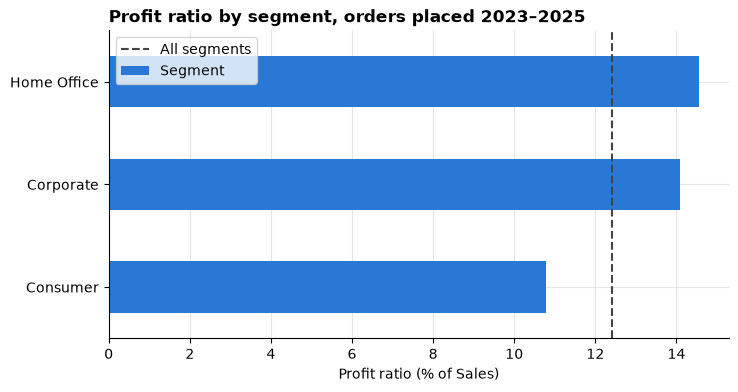

In [7]:
by_segment = segment_kpis.drop("All")

by_segment["profit_ratio_pct"].sort_values().plot(
    kind="barh", title="Profit ratio by segment, orders placed 2023–2025", label="Segment"
)
plt.axvline(profit_ratio * 100, color="#444444", linestyle="--", label="All segments")
plt.xlabel("Profit ratio (% of Sales)")
plt.ylabel("")
plt.legend()
plt.show()

> **Read the chart**
>
> Which segment is above the line and which is below? Now look back at the Sales column. Is the segment with the most Sales also the one with the highest profit ratio?

---

## Part 4: Check that it reconciles

A table you cannot reconcile is a table you cannot trust. `by_segment` is the table without the **All** row.

In [8]:
print("Sales:  segments add up to", round(by_segment["sales"].sum(), 2), "| overall", round(total_sales, 2))
print("Profit: segments add up to", round(by_segment["profit"].sum(), 2), "| overall", round(total_profit, 2))
print("Orders: segments add up to", by_segment["orders"].sum(), "| overall", total_orders)

Sales:  segments add up to 1580966.82 | overall 1580966.82
Profit: segments add up to 196370.47 | overall 196370.47
Orders: segments add up to 3388 | overall 3388


Orders can only add up if every order belongs to **exactly one** segment. Check it: count the different segments inside each order and look at the largest count.

In [9]:
segments_per_order = df.groupby("order_id")["segment"].nunique()
print("Largest number of segments in one order:", segments_per_order.max())

Largest number of segments in one order: 1


Tick each check in your evidence log:

- [ ] The segment **Sales** add up to the overall total.
- [ ] The segment **Profit** values add up to the overall total.
- [ ] The segment **Orders** add up to the overall total, because each order sits in one segment.
- [ ] The overall **AOV** is total Sales ÷ total Orders, **not** the average of the segment AOVs.
- [ ] The overall **profit ratio** is total Profit ÷ total Sales, **not** the average of the segment ratios.

> **If a total looks wrong**
>
> Check that every measure used the same rows (the same filters), and that the **All** row was recalculated from totals rather than added up.

---

## Part 5: Independent work

Building the table step by step takes several cells. To repeat it quickly on filtered data, we package the same steps as a **function**: a named recipe you can reuse. You do not need to write functions yet; just read it and see that each line matches a step above.

In [10]:
def kpi_table(data, by):
    """Five measures for each group in the column `by`, plus an 'All' row from totals."""
    table = data.groupby(by).agg(
        sales=("sales", "sum"),
        orders=("order_id", "nunique"),
        profit=("profit", "sum"),
    )
    table.loc["All"] = [data["sales"].sum(), data["order_id"].nunique(), data["profit"].sum()]
    table["orders"] = table["orders"].astype(int)
    table["aov"] = table["sales"] / table["orders"].replace(0, float("nan"))
    table["profit_ratio_pct"] = table["profit"] / table["sales"].replace(0, float("nan")) * 100
    return table[["sales", "orders", "aov", "profit", "profit_ratio_pct"]].round(2)


kpi_table(df, "segment")

,sales,orders,aov,profit,profit_ratio_pct
segment,,,,,
Consumer,"835,747.86",1738,480.87,"90,101.17",10.78
Corporate,"467,562.02",1044,447.86,"65,842.38",14.08
Home Office,"277,656.95",606,458.18,"40,426.92",14.56
All,"1,580,966.82",3388,466.64,"196,370.47",12.42


It gives the same table as Part 3. The `.replace(0, float("nan"))` parts make a zero denominator show `NaN` (*not available*) instead of a misleading number.

### A. Filter by region

1. Run the cell below for the West region.
2. Change `"West"` to `"East"`, `"Central"` or `"South"` and run it again.
3. Record all five measures for each segment in your chosen region.
4. Write two sentences: does the ranking of segments by profit ratio change inside this region?

> **Your turn:** change the code in the next cell and run it again.

In [11]:
selected = df[df["region"] == "West"]
kpi_table(selected, "segment")

,sales,orders,aov,profit,profit_ratio_pct
segment,,,,,
Consumer,"256,522.36",562,456.45,"36,016.12",14.04
Corporate,"140,280.49",324,432.96,"18,655.27",13.30
Home Office,"84,769.72",203,417.58,"10,702.62",12.63
All,"481,572.58",1089,442.22,"65,374.01",13.58


> **A filter changes every measure**
>
> The filter removes rows **before** anything is added up. So Sales, Orders, Profit and both ratios all describe the filtered rows only, including the **All** row.

### B. Look inside one category

1. Run the cell below, which keeps only Furniture lines.
2. Change `"Furniture"` to `"Office Supplies"` or `"Technology"`.
3. Here AOV no longer means full basket value. It means *"Sales of this category's lines per order that contains this category"*. Change the second `"aov"` in the `rename` line to a name that says so, for example `"category_sales_per_order"`.

> **Your turn:** change the code in the next cell and run it again.

In [12]:
selected = df[df["category"] == "Furniture"]
category_view = kpi_table(selected, "segment")
category_view = category_view.rename(columns={"aov": "aov"})
category_view

,sales,orders,aov,profit,profit_ratio_pct
segment,,,,,
Consumer,"283,170.14",635,445.94,"5,364.12",1.89
Corporate,"169,851.05",394,431.09,"6,636.46",3.91
Home Office,"82,413.65",206,400.07,"4,380.18",5.31
All,"535,434.83",1235,433.55,"16,380.76",3.06


### C. Do category orders add up?

Now group by **category** instead of segment, with no filter.

1. Run the cell and compare the two printed numbers.
2. In one sentence, explain why they are different. *Think about an order that contains both a chair and some paper.*

> **Your turn:** change the code in the next cell and run it again.

In [13]:
by_category = kpi_table(df, "category")
print("Category orders added up:", by_category.drop("All")["orders"].sum())
print("Overall orders:          ", by_category.loc["All", "orders"])
by_category

Category orders added up: 4779
Overall orders:           3388


,sales,orders,aov,profit,profit_ratio_pct
category,,,,,
Furniture,"535,434.83",1235,433.55,"16,380.76",3.06
Office Supplies,"478,057.88",2516,190.01,"84,280.42",17.63
Technology,"567,474.11",1028,552.02,"95,709.29",16.87
All,"1,580,966.82",3388,466.64,"196,370.47",12.42


---

## Part 6: Debugging challenge

A colleague sends you this summary:

> *"Our overall profit ratio is the average of the three segment ratios. And our average order value is total Sales divided by the number of rows."*

Their code is below.

1. Run it to calculate the colleague's two numbers.
2. Compare them with the **All** row of your segment table in Part 3.
3. Explain each mistake in one sentence.
4. Which segment has the most influence on the correct overall profit ratio, and why? Add a line `print(by_segment["sales"] / total_sales * 100)` to see each segment's share of Sales.

> **Your turn:** change the code in the next cell and run it again.

In [14]:
colleague_ratio = by_segment["profit_ratio_pct"].mean()
colleague_aov = df["sales"].sum() / len(df)

print("Colleague's overall profit ratio (%):", round(colleague_ratio, 1))
print("Colleague's AOV:                     ", round(colleague_aov, 2))

Colleague's overall profit ratio (%): 13.1
Colleague's AOV:                      231.98


> **Think about weights**
>
> A segment with much more Sales should pull the overall ratio more strongly than a small segment. Does a simple average of the three ratios allow that? And what does one **row** represent: an order, or one product line within an order?

---

## Part 7: Make a recommendation

Write **five sentences** to the retail head:

1. **Recommendation:** which segment to investigate first.
2. **Evidence 1:** one measure, with its value from your table and how it compares with the **All** row.
3. **Evidence 2:** a second, different measure.
4. **Limitation:** one thing this data cannot tell you. For example, it shows which segment *looks* different; it does not show *why*.
5. **Next check:** one specific piece of evidence to request before changing promotions.

Copy the numbers from **the output above**; do not retype them from memory.

> **Association, not cause**
>
> If a segment with more discounts has a lower profit ratio, that is a pattern worth investigating. It is not proof that the discounts caused it. Other differences between segments, such as product mix, could explain it.

---

## Validation checklist

Before submitting, confirm:

- [ ] Every measure uses the same filters and date scope.
- [ ] Orders are counted with `nunique`, not as rows.
- [ ] AOV and Profit ratio are calculated from totals.
- [ ] Segment Sales, Profit and Orders reconcile with the **All** row.
- [ ] Money is labelled "source monetary units", with no currency symbol.
- [ ] A `NaN` ratio is described as "not available", not 0%.
- [ ] The recommendation names a limitation and a next check.

---

## Exit ticket

1. Why is the average of three segment ratios not the overall ratio?
2. What does a `NaN` AOV or profit ratio mean?
3. One question you would want answered before acting on your recommendation.

## After the lesson

- Finish the region and category work from Part 5.
- Correct the colleague's summary from Part 6 and add it to your evidence log.
- Next: [Lesson 4](04_trends_returns_dashboard.md), where we look at monthly trends and the returns list.